# Milestone 1 — Housing Dataset: Loading, EDA and Cleaning
**Data Engineering and Visualization — Winter 2026**  
**Author:** Member 1 (Housing dataset and cleaning)

## 1. Dataset overview and selection rationale

| Item | Details |
|---|---|
| Dataset | **DOB NOW: Build – Job Application Filings** (catalog ID **H5**) |
| Source | NYC Open Data — https://data.cityofnewyork.us/resource/w9ak-ipjd |
| Dataset ID | `w9ak-ipjd` (**verify it in the dataset's URL before running**) |
| Geographic attributes | Borough, ZIP code, block/lot, latitude/longitude |
| Temporal attributes | Filing date (also status dates) |
| Why this dataset | Every filing has a location and a date, so it can be aggregated to *ZIP code × month* and matched with transportation data (T4: SIRTA serious-injury crashes). `job_type` lets us isolate **new buildings**, and proposed dwelling units / stories measure the *size* of each project. |
| Known issues to check | Several filings per job (initial and subsequent filings), missing ZIP / coordinates, mixed borough spellings, extreme project sizes, and text-typed numeric/date columns. |

**Planned integration level (to be confirmed by Member 3):** ZIP code × month, with housing metrics (number of new-building filings, proposed units) aligned to transportation metrics (SIRTA crashes and killed-or-seriously-injured counts, KSI).

### Prompts used
*(The project requires listing the prompts used. Paste yours here and keep adding to this list.)*
1. "Provide the code in blocks for: select and load the housing dataset, explore columns/types/missing/duplicates/outliers, clean and standardize, document decisions, and develop 2 research questions and 2 visualizations."

## 2. Setup
All settings live in one cell so the team can change them in one place.

In [29]:
import re
import warnings
from urllib.parse import urlencode

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

# ---------------- Configuration ----------------
HOUSING_ID = "w9ak-ipjd"      # DOB NOW: Build - Job Application Filings (verify in the URL!)
SIRTA_ID = "xeqp-qz8h"        # T4: Serious Injury Response, Tracking & Analysis Program (SIRTA) crashes
START_DATE = "2019-01-01"     # DOB NOW started around 2018-2019, so earlier filings are sparse
API_URL = "https://data.cityofnewyork.us/resource/{}.csv"

# NYC sanity bounds used for coordinate validation
NYC_LAT_RANGE = (40.45, 40.95)
NYC_LON_RANGE = (-74.30, -73.65)
PANEL_START = "2022-01"       # analysis window: new-building filings only appear in this system from 2021 on (see 6.1)
MAX_UNITS = 5000              # domain rule: no single NYC filing plausibly has more dwelling units than this

## 3. Load the housing dataset

We follow the project's **Listing 1**: download the full table from NYC Open Data using the dataset ID in its URL.

**Fallback (Listing 2):** if the full download is too large or slow for the Colab session, set `USE_FULL_DOWNLOAD = False`.
The notebook then downloads a filtered sample through the API (`$where filing_date >= 2019-01-01`).
If you have to use the fallback, write the justification in the Markdown cell below the load cell (e.g., "the full table has N rows and crashed the session; DOB NOW began around 2019, so earlier filings are sparse and would not be comparable with the transportation data").

Note: the CSV download uses the *display* column names (e.g. `Job Filing Number`), while the API uses `job_filing_number`. Section 4 converts all names to `snake_case`, so both work.

In [30]:
BASE_URL = "https://data.cityofnewyork.us/api/views/{}/rows.csv?accessType=download"   # Listing 1 of the project brief
USE_FULL_DOWNLOAD = True      # True = Listing 1 (whole table); False = Listing 2 (filtered sample, must be justified)

def fetch_socrata(dataset_id, **params):
    # Listing 2 style: download a filtered slice through the API (also used for the temporary crash stub in section 8)
    url = API_URL.format(dataset_id) + "?" + urlencode(params)
    return pd.read_csv(url, low_memory=False)

if USE_FULL_DOWNLOAD:
    df_raw = pd.read_csv(BASE_URL.format(HOUSING_ID), low_memory=False)
else:
    probe = fetch_socrata(HOUSING_ID, **{"$limit": 5})                 # 5 rows to see the API column names
    date_col_api = next((c for c in ["filing_date", "filed_date", "job_filing_date"] if c in probe.columns), None)
    params = {"$limit": 2_000_000, "$order": ":id"}
    if date_col_api:
        params["$where"] = f"{date_col_api} >= '{START_DATE}T00:00:00'"
    df_raw = fetch_socrata(HOUSING_ID, **params)
    if len(df_raw) >= params["$limit"]:
        print("WARNING: the row limit was reached - raise $limit or tighten the filter.")

print(f"Rows: {len(df_raw):,} | Columns: {df_raw.shape[1]}")
print(list(df_raw.columns))
assert df_raw.shape[1] >= 9, "The project requires at least 9 columns."
df_raw.head()

Rows: 165,992 | Columns: 95
['Job Filing Number', 'Filing Status', 'House No', 'Street Name', 'Borough', 'Block', 'LOT', 'Bin', 'Commmunity - Board', 'Work on Floor', 'Apt./Condo No(s)', 'Applicant Professional Title', 'Applicant License #', 'Applicant First Name', 'Applicants Middle Initial', 'Applicant Last Name', "Owner's Business Name", 'Applicant Street Name', 'Applicant City', 'Applicant State', 'Applicant Zip', 'Filing Representative First Name', 'Filing Representative Middle Initial', 'Filing Representative Last Name', 'Filing Representative Business Name', 'Filing Representative Street Name', 'Filing Representative City', 'Filing Representative State', 'Filing Representative Zip', 'Sprinkler (Work Type)', 'Plumbing (Work Type)', 'Stand Pipe (Work Type)', 'Antenna (Work Type)', 'Sign (Work Type)', 'Curb Cut (Work Type)', 'Fence (Work Type)', 'Scaffold (Work Type)', 'Shed (Work Type)', 'Initial Cost', 'Total Construction Floor Area', 'Review Building Code', 'Little E', 'Unmapped

,Job Filing Number,Filing Status,House No,Street Name,Borough,Block,LOT,Bin,Commmunity - Board,Work on Floor,Apt./Condo No(s),Applicant Professional Title,Applicant License #,Applicant First Name,Applicants Middle Initial,Applicant Last Name,Owner's Business Name,Applicant Street Name,Applicant City,Applicant State,Applicant Zip,Filing Representative First Name,Filing Representative Middle Initial,Filing Representative Last Name,Filing Representative Business Name,Filing Representative Street Name,Filing Representative City,Filing Representative State,Filing Representative Zip,Sprinkler (Work Type),...,Earth Work (Work Type),Foundation (Work Type),General Construction (Work Type),Mechanical Systems (Work Type),Place of Assembly (Work Type),Protection Mechanical Methods (Work Type),Sidewalk Shed (Work Type),Structural (Work Type),Support of Excavation (Work Type),Temporary Place of Assembly (Work Type),Green Roof (Work Type),Solar (Work Type),Full Demolition (Work Type),Suspended Scaffold (Work Type),Job Type,Latitude,Longitude,Postcode,Council District,Census Tract,BBL,NTA,Approved Date,Signoff Date,Applicant Business Name,Owner First Name,Owner Last Name,Owner Type,Job Description,Filing Review Type
0,B00319790-I1,LOC Issued,367,12 STREET,Brooklyn,"1,024.00",74.00,"3,023,048.00",306.00,"Basement/Sub-basement, Cellar, Floor Number(s)...",NaN,RA,030377,MICHELLE,NaN,KROCHMAL,PR,"460 11TH ST., #2",BROOKLYN,NY,11215,HETIENE,NaN,RUDOLPHO,BURNHAM NATIONWIDE INC,86 Chambers Street,New York,NY,10007,NO,...,NO,NO,NO,NO,NO,NO,NO,NO,No,NO,NO,NO,NO,NO,Alteration,40.67,-73.98,"11,215.00",39.00,151.00,"3,010,240,074.00",Park Slope,03/17/2020 09:28:59 AM,07/26/2021,"FILAMENT ARCHITECTURE STUDIO, PLLC",Ilya,Finkler,Individual,PLUMBING MODIFICATIONS ON EXISTING 1 FAMILY HO...,Standard Plan Examination
1,B00422847-I1,Incomplete,761,MACON STREET,Brooklyn,"1,493.00",48.00,"3,040,031.00",303.00,Floor Number(s) 001 through 02,NaN,PE,054573,BRIAN,NaN,ROHAN,PR,2116,MERRICK,NY,11566,VINCENZO,NaN,D'ANGELO,"VRD DEVELOPMENT, LLC",2116 Merrick Avenue,Merrick,NY,11793,NO,...,NO,NO,NO,NO,NO,NO,NO,NO,No,NO,NO,NO,NO,NO,Alteration,40.68,-73.92,"11,233.00",41.00,377.00,"3,014,930,048.00",Bedford-Stuyvesant (East),NaN,NaN,"ROHAN ENGINEERING, PC",PAUL,REIMER,Individual,PLUMBING WORK FOR MODIFICATIONS TO EXISTING KI...,Standard Plan Examination
2,B00455182-I1,Permit Entire,281,MONROE STREET,Brooklyn,"1,814.00",73.00,"3,051,205.00",303.00,Ground Floor,NaN,PE,086610,RAFI,NaN,HAMID,TOPLINE NYC CONTRACTING,12 1/2 RAYNHAM DRIVE,SYOSSET,NY,11791,JOGINDER,NaN,SINGH,TOPLINE NYC CONTRACTING,92-19 101ST AVENUE,OZONE PARK,NY,11416,NO,...,NO,NO,NO,NO,NO,NO,YES,NO,No,NO,NO,NO,NO,NO,Alteration,40.69,-73.95,"11,216.00",36.00,265.00,"3,018,140,073.00",Bedford-Stuyvesant (West),01/16/2021 03:05:44 PM,NaN,"SYED ENGINEERING, P.C.",JOGINDER,SINGH,Individual,PROPOSED INSTALLATION OF HEAVY DUTY SIDEWALK S...,Professional Certification
3,B00244768-P3,Approved,22,MONROE STREET,Brooklyn,"1,987.00",21.00,"3,057,064.00",303.00,"Cellar, Floor Number(s) 2 through 3, Floor Num...","Apr A, Apt B",RA,018485,Steven,G,Zirinsky,PR,44-02 11 STREET,LONG ISLAND CITY,NY,11101,LESLIE,NaN,MCKENZIE,LESLIE MCKENZIE,1759 ALBANY AVENUE,BROOKLYN,NY,11210,NO,...,NO,NO,NO,NO,NO,NO,NO,NO,No,NO,NO,NO,NO,NO,Alteration,40.68,-73.96,"11,238.00",36.00,229.00,"3,019,870,021.00",Bedford-Stuyvesant (West),06/02/2022 01:28:51 PM,NaN,ZIRINSKY ARCHITECTURE PC,PETER,PANKEN,Individual,Renovation of upper portion of two family dwel...,Standard Plan Examination
4,B00464221-S2,Permit Entire,29,MARCONI PLACE,Brooklyn,"1,566.00",4.00,"3,042,533.00",316.00,"Cellar, Floor Number(s) 2 through 2",NaN,PE,076278,SEBERT,-,DYER,PR,95-05 SUTPHIN BLVD,JAMAICA,NY,11435,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO,...,NO,NO,YES,NO,NO,NO,NO,NO,No,NO,NO,NO,NO,NO,Alteration,40.68,-73.91,"11,233.00",41.00,301.00,"3,015,660,004.00",Ocean Hill,11/13/2023 03:26:00 PM,NaN,BUILDING ENGINEERING SYSTEMS PLLC,Margaret,Aloba,Individual,NaN,Professional Certificati

**Record the snapshot.** NYC Open Data tables are refreshed, so the same download can return different row counts on different days. Write the date and row count below in your README so teammates and graders know which snapshot your results come from, and share the saved `housing_clean.csv` so everyone analyzes identical data.

In [31]:
from datetime import date
print(f"Snapshot: downloaded on {date.today()} | dataset {HOUSING_ID} | rows = {len(df_raw):,} | columns = {df_raw.shape[1]}")

Snapshot: downloaded on 2026-10-24 | dataset w9ak-ipjd | rows = 165,992 | columns = 95


## 4. Exploratory Data Analysis (before cleaning)
We work on a copy so the raw download stays untouched.

In [32]:
df = df_raw.copy()

# Standardize column names to lowercase_snake_case (robust to CSV vs API naming)
df.columns = [re.sub(r"\W+", "_", c.strip().lower()).strip("_") for c in df.columns]

# Blank strings are really missing values
obj_cols = df.select_dtypes(include="object").columns
df[obj_cols] = df[obj_cols].replace(r"^\s*$", np.nan, regex=True)

overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "n_unique": df.nunique(),
    "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
print(f"Shape: {df.shape} | Memory: {df.memory_usage(deep=True).sum() / 1e6:,.1f} MB")
display(overview)

Shape: (165992, 95) | Memory: 732.2 MB


,dtype,non_null,n_unique,example
job_filing_number,str,165992,165964,B00319790-I1
filing_status,str,165989,42,LOC Issued
house_no,str,165989,13340,367
street_name,str,165989,5696,12 STREET
borough,str,165989,5,Brooklyn
...,...,...,...,...
owner_first_name,str,165732,14570,Ilya
owner_last_name,str,165735,22969,Finkler
owner_type,str,165942,10,Individual
job_description,str,163315,103180,PLUMBING MODIFICATIONS ON EXISTING 1 FAMILY HO...


### 4.1 Map the columns we need
Different exports name columns slightly differently, so we look each one up from a list of candidates and fail loudly if a required one is missing.

In [33]:
COLUMN_CANDIDATES = {
    "job_filing_number":       ["job_filing_number", "job_number"],
    "filing_date":             ["filing_date", "filed_date", "job_filing_date"],
    "borough":                 ["borough", "boro", "borough_name"],
    "zip_code":                ["zip_code", "zip", "zipcode", "postcode"],
    "latitude":                ["latitude", "gis_latitude"],
    "longitude":               ["longitude", "gis_longitude"],
    "job_type":                ["job_type", "job_type_description"],
    "filing_status":           ["filing_status", "job_status"],
    "proposed_dwelling_units": ["proposed_dwelling_units", "proposed_dwelling_unit"],
    "existing_dwelling_units": ["existing_dwelling_units", "existing_dwelling_unit"],
    "proposed_stories":        ["proposed_no_of_stories", "proposed_stories", "proposed_number_of_stories"],
    "proposed_height":         ["proposed_height", "proposed_building_height"],
}
REQUIRED = ["job_filing_number", "filing_date", "borough", "zip_code", "job_type"]

def resolve_columns(frame, candidates):
    """Return {canonical_name: actual_column or None}."""
    return {canon: next((c for c in opts if c in frame.columns), None) for canon, opts in candidates.items()}

COLS = resolve_columns(df, COLUMN_CANDIDATES)
display(pd.Series(COLS, name="actual_column_in_data").to_frame())

missing_required = [k for k in REQUIRED if COLS[k] is None]
assert not missing_required, (
    f"Required columns not found: {missing_required}. Compare with df.columns and edit COLUMN_CANDIDATES "
    f"(if there is no ZIP column, derive it from latitude/longitude or discuss with Member 3)."
)

,actual_column_in_data
job_filing_number,job_filing_number
filing_date,filing_date
borough,borough
zip_code,postcode
latitude,latitude
longitude,longitude
job_type,job_type
filing_status,filing_status
proposed_dwelling_units,proposed_dwelling_units
existing_dwelling_units,existing_dwelling_units


### 4.2 Missing values

,missing_n,missing_pct
request_legalization,165837,99.91
includes_permanent_removal,165837,99.91
apt_condo_no_s,162152,97.69
filing_representative_middle_initial,155257,93.53
built_2_b_information_value,148422,89.42
built_2_a_information_value,148422,89.42
built_2_information_value,148422,89.42
built_1_information_value,148422,89.42
existing_height,125610,75.67
applicants_middle_initial,120919,72.85


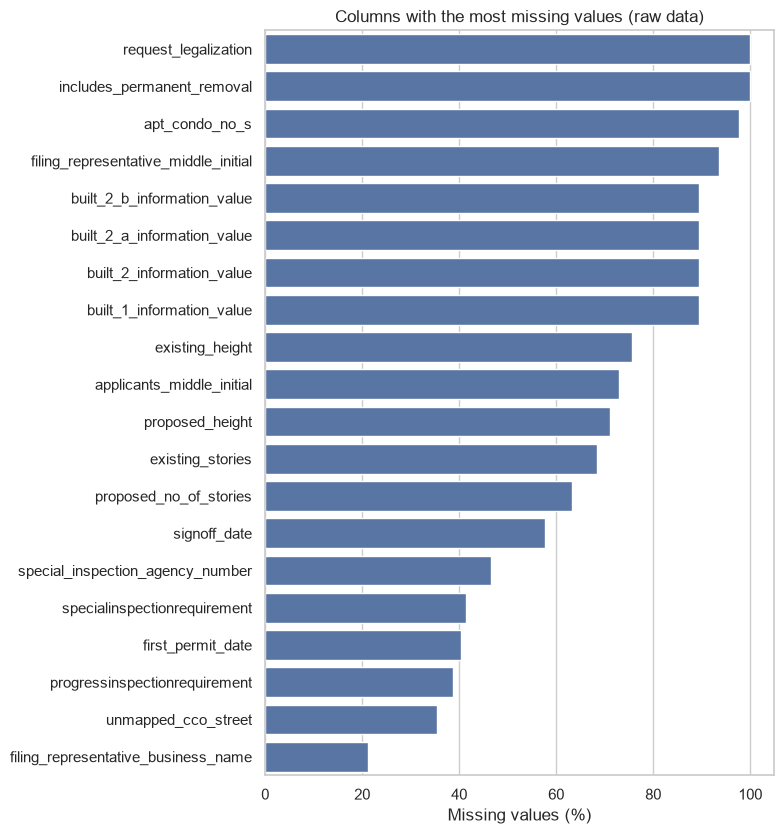

In [34]:
missing = pd.DataFrame({
    "missing_n": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100,
}).sort_values("missing_pct", ascending=False)
display(missing[missing.missing_n > 0].head(30))

top = missing[missing.missing_n > 0].head(20)
if len(top):
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(top) + 1.5))
    sns.barplot(x=top.missing_pct, y=top.index, color="#4C72B0", ax=ax)
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("")
    ax.set_title("Columns with the most missing values (raw data)")
    plt.tight_layout()
    plt.show()

### 4.3 Duplicates
A single *job* can have several filings (initial and subsequent filings share the same job number with a different suffix, e.g. `M00123456-I1`, `-S1`).
We check (a) fully identical rows, (b) repeated filing numbers, and (c) repeated jobs.

In [35]:
jf = COLS["job_filing_number"]

full_dups = df.duplicated().sum()
filing_dups = df.duplicated(subset=[jf]).sum()
job_number_base = df[jf].astype(str).str.split("-").str[0]
job_dups = job_number_base.duplicated().sum()

print(f"Fully identical rows:            {full_dups:,}")
print(f"Repeated job filing numbers:     {filing_dups:,}")
print(f"Repeated jobs (same base number): {job_dups:,}  ({job_dups / len(df):.1%} of rows)")

Fully identical rows:            0
Repeated job filing numbers:     28
Repeated jobs (same base number): 42,599  (25.7% of rows)


### 4.4 Outliers
We use the **IQR rule** (values beyond Q3 + 1.5×IQR, or Q1 − 1.5×IQR) as a *screening* tool and apply **domain rules** for the final decision, because large projects are real, not errors.

,min,median,p99,max,iqr_upper_fence,n_above_fence,n_negative
column,,,,,,,
proposed_dwelling_units,0.00,2.00,483.00,"325,437.00",40.00,26415,0
existing_dwelling_units,0.00,2.00,451.03,"325,437.00",22.50,26803,0
proposed_stories,1.00,4.00,56.00,"92,501.00",14.50,8312,0
proposed_height,0.00,43.00,664.00,"33,798.00",150.00,6159,0


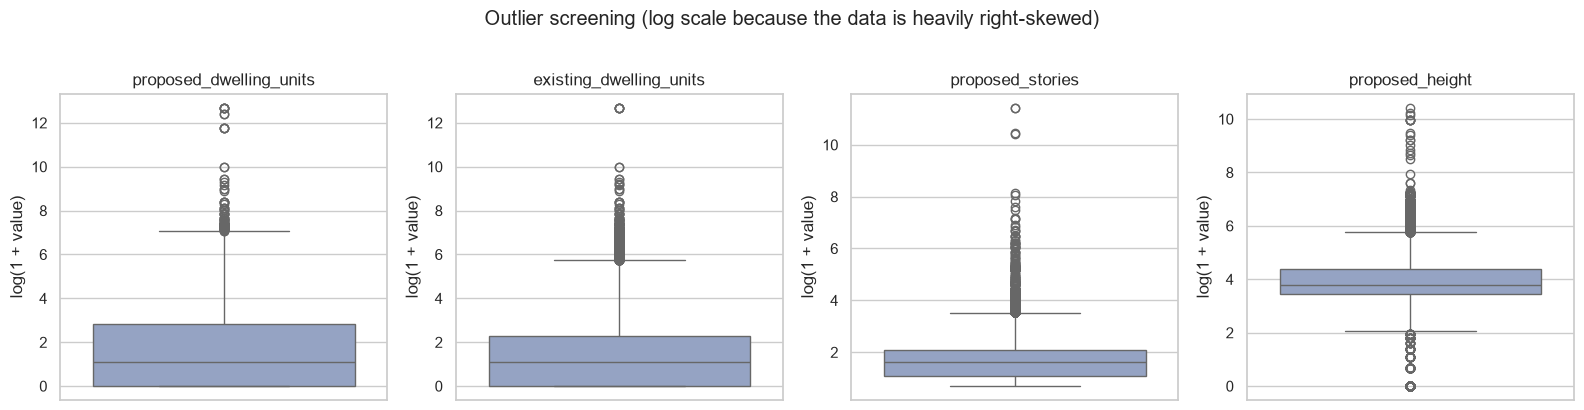

In [36]:
def iqr_bounds(series, k=1.5):
    """Tukey fences. Returns (lower, upper)."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

numeric_targets = ["proposed_dwelling_units", "existing_dwelling_units", "proposed_stories", "proposed_height"]
numeric_targets = [c for c in numeric_targets if COLS[c] is not None]

rows = []
for canon in numeric_targets:
    s = pd.to_numeric(df[COLS[canon]], errors="coerce")
    lo, hi = iqr_bounds(s.dropna())
    rows.append({"column": canon, "min": s.min(), "median": s.median(), "p99": s.quantile(0.99),
                 "max": s.max(), "iqr_upper_fence": hi,
                 "n_above_fence": int((s > hi).sum()), "n_negative": int((s < 0).sum())})
display(pd.DataFrame(rows).set_index("column"))

if numeric_targets:
    fig, axes = plt.subplots(1, len(numeric_targets), figsize=(4 * len(numeric_targets), 4))
    axes = np.atleast_1d(axes)
    for ax, canon in zip(axes, numeric_targets):
        s = pd.to_numeric(df[COLS[canon]], errors="coerce").dropna()
        sns.boxplot(y=np.log1p(s[s >= 0]), ax=ax, color="#8DA0CB")
        ax.set_title(canon)
        ax.set_ylabel("log(1 + value)")
    plt.suptitle("Outlier screening (log scale because the data is heavily right-skewed)", y=1.02)
    plt.tight_layout()
    plt.show()

### 4.5 Inconsistent data
Checks: borough spellings, ZIP formats, coordinates outside NYC, impossible dates, and the mix of job types.

In [37]:
print("Borough values:")
display(df[COLS["borough"]].value_counts(dropna=False))

zip_series = df[COLS["zip_code"]].astype(str)
print("\nZIP string lengths:")
display(zip_series.str.len().value_counts().head())

if COLS["latitude"] and COLS["longitude"]:
    lat = pd.to_numeric(df[COLS["latitude"]], errors="coerce")
    lon = pd.to_numeric(df[COLS["longitude"]], errors="coerce")
    outside = (~lat.between(*NYC_LAT_RANGE) | ~lon.between(*NYC_LON_RANGE)) & lat.notna() & lon.notna()
    print(f"\nCoordinates outside the NYC bounding box: {outside.sum():,}")

dates = pd.to_datetime(df[COLS["filing_date"]], errors="coerce")
print(f"\nUnparseable filing dates: {dates.isna().sum():,}")
print(f"Date range: {dates.min()}  ->  {dates.max()}")
print(f"Filing dates in the future: {(dates > pd.Timestamp.today()).sum():,}")

print("\nJob types:")
display(df[COLS["job_type"]].value_counts(dropna=False).head(15))

Borough values:


borough
Brooklyn         104074
Manhattan         32878
Queens            16670
Bronx              8161
Staten Island      4206
NaN                   3
Name: count, dtype: int64


ZIP string lengths:


postcode
7.00    165244
Name: count, dtype: int64


Coordinates outside the NYC bounding box: 0

Unparseable filing dates: 546
Date range: 2016-09-14 20:00:00  ->  2026-10-13 00:00:00
Filing dates in the future: 0

Job types:


job_type
Alteration                                                144054
New Building                                                9052
Alteration CO                                               6778
No Work                                                     2761
ALT-CO - New Building with Existing Elements to Remain      2562
Full Demolition                                              782
NaN                                                            3
Name: count, dtype: int64

### 4.6 Follow-up checks on suspicious values
(a) Filing dates that could not be parsed — are they blanks, or a different format we would wrongly discard?  
(b) The largest dwelling-unit values — real mega-projects or entry errors? This decides the `MAX_UNITS` domain rule used in cleaning.

In [38]:
raw_dates = df[COLS["filing_date"]]
parsed = pd.to_datetime(raw_dates, errors="coerce")
unparsed = raw_dates[parsed.isna()]
print(f"Unparseable filing dates: {len(unparsed):,}  (of which truly blank: {int(unparsed.isna().sum()):,})")
print("Examples of non-blank values that failed to parse:")
display(unparsed.dropna().head(10))

Unparseable filing dates: 546  (of which truly blank: 546)
Examples of non-blank values that failed to parse:


Series([], Name: filing_date, dtype: str)

In [39]:
unit_cols = [c for c in [COLS["job_filing_number"], COLS["job_type"], COLS["borough"], COLS["proposed_dwelling_units"]] if c]
largest = (df.assign(_units=pd.to_numeric(df[COLS["proposed_dwelling_units"]], errors="coerce"))
             .nlargest(10, "_units")[unit_cols])
print(f"Ten largest proposed_dwelling_units values (cleaning sets values above {MAX_UNITS:,} to missing):")
display(largest)

Ten largest proposed_dwelling_units values (cleaning sets values above 5,000 to missing):


,job_filing_number,job_type,borough,proposed_dwelling_units
14318,B00336793-I1,Alteration,Brooklyn,"325,437.00"
14369,B00336793-P2,Alteration,Brooklyn,"325,437.00"
14450,B00336793-P1,Alteration,Brooklyn,"325,437.00"
14514,B00336793-P4,Alteration,Brooklyn,"325,437.00"
15062,B00336793-P3,Alteration,Brooklyn,"325,437.00"
53688,B00292161-S1,Alteration,Brooklyn,"243,295.00"
53784,B00292161-P1,Alteration,Brooklyn,"243,295.00"
1987,B00219653-P1,Alteration,Brooklyn,"126,419.00"
18119,B00219653-P2,Alteration,Brooklyn,"126,419.00"
25450,B00219653-I1,Alteration,Brooklyn,"126,419.00"


## 5. Cleaning and standardization

### Decisions (and the alternatives we considered)

| Issue | Decision | Why / alternative |
|---|---|---|
| Column names | Rename to a **canonical schema** (`borough`, `zip_code`, `filing_date`, ...) | Gives Members 2, 3, 5 and 6 stable names regardless of API vs CSV naming. |
| Borough spellings | Uppercase and map aliases/codes to the 5 official names; unknown → missing | Needed as a join/filter key. |
| ZIP codes | Keep as a **5-character string**; invalid or non-NYC ZIPs → missing | Numeric ZIPs lose leading zeros and break joins. Not imputed: guessing a ZIP would put a project in the wrong neighborhood. |
| Dates | Parse to datetime; future dates → missing; add `year`, `month`, `year_month` | `year_month` is the planned join key. |
| Duplicates | Drop identical rows, then keep **one row per job** (the earliest filing) | Initial and subsequent filings describe the same project; counting both would inflate construction activity. Alternative: keep all filings and count unique jobs later (more flexible, but easier to misuse). |
| Missing coordinates | **Keep the rows** and add `has_coordinates` | The ZIP × month integration does not need coordinates; dropping them would discard valid projects. |
| Missing ZIP | **Keep** but flag with `has_zip`; ZIP-level analysis uses only rows with a ZIP | Dropping would bias against places with sloppier records; flagging keeps the option open. |
| Impossible values | Negative units, units > 5,000, stories > 110, height > 1,500 ft → missing | Domain rules (raw data contains entries such as 325,437 units; the tallest NYC building has about 100 floors). Set to missing, not dropped, so the rest of the filing is kept. |
| Statistical outliers | **Keep** but add `is_extreme_units` (units above Q3 + 3×IQR of non-zero values) | Very large developments are real and important for our story; they are flagged, not removed. |
| New buildings | `is_new_building` = job type is **exactly** "New Building" | The housing-growth signal. "ALT-CO - New Building with Existing Elements to Remain" is a certificate-of-occupancy *alteration*, so it is excluded. |

In [40]:
BOROUGH_MAP = {
    "MANHATTAN": "MANHATTAN", "NEW YORK": "MANHATTAN", "MN": "MANHATTAN", "1": "MANHATTAN",
    "BRONX": "BRONX", "THE BRONX": "BRONX", "BX": "BRONX", "2": "BRONX",
    "BROOKLYN": "BROOKLYN", "BKLYN": "BROOKLYN", "BK": "BROOKLYN", "KINGS": "BROOKLYN", "3": "BROOKLYN",
    "QUEENS": "QUEENS", "QN": "QUEENS", "4": "QUEENS",
    "STATEN ISLAND": "STATEN ISLAND", "SI": "STATEN ISLAND", "RICHMOND": "STATEN ISLAND", "5": "STATEN ISLAND",
}

def clean_housing(raw, cols):
    """Return (clean_df, cleaning_log). Every step records how many rows/values it changed."""
    log = []
    def record(step, before, after, note=""):
        log.append({"step": step, "rows_before": before, "rows_after": after, "note": note})

    # --- 1. Canonical schema (missing optional columns become NaN so later code never breaks)
    out = pd.DataFrame({canon: (raw[actual] if actual else np.nan) for canon, actual in cols.items()})
    n0 = len(out)

    # --- 2. Strings: trim and standardize case
    out["borough"] = (out["borough"].astype(str).str.strip().str.upper()
                      .replace({"NAN": np.nan}).map(BOROUGH_MAP))
    for c in ["job_type", "filing_status"]:
        out[c] = out[c].astype("string").str.strip().str.title()
    out["job_filing_number"] = out["job_filing_number"].astype("string").str.strip().str.upper()

    # --- 3. ZIP codes: exactly 5 digits and inside the NYC range (10001-11697)
    zip5 = out["zip_code"].astype(str).str.extract(r"(\d{5})")[0]
    zip_num = pd.to_numeric(zip5, errors="coerce")
    out["zip_code"] = zip5.where(zip_num.between(10001, 11697))
    out["has_zip"] = out["zip_code"].notna()

    # --- 4. Dates
    out["filing_date"] = pd.to_datetime(out["filing_date"], errors="coerce")
    out.loc[out["filing_date"] > pd.Timestamp.today(), "filing_date"] = pd.NaT   # future dates are errors
    out["year"] = out["filing_date"].dt.year.astype("Int64")
    out["month"] = out["filing_date"].dt.month.astype("Int64")
    out["year_month"] = out["filing_date"].dt.strftime("%Y-%m")                   # planned join key

    # --- 5. Numeric columns + domain rules
    for c in ["proposed_dwelling_units", "existing_dwelling_units", "proposed_stories", "proposed_height",
              "latitude", "longitude"]:
        out[c] = pd.to_numeric(out[c], errors="coerce")
    for c in ["proposed_dwelling_units", "existing_dwelling_units"]:
        out.loc[out[c] < 0, c] = np.nan
        out.loc[out[c] > MAX_UNITS, c] = np.nan      # entry errors (e.g. 325,437 units); see section 4.6
    out.loc[(out["proposed_stories"] < 0) | (out["proposed_stories"] > 110), "proposed_stories"] = np.nan
    out.loc[(out["proposed_height"] < 0) | (out["proposed_height"] > 1500), "proposed_height"] = np.nan

    # --- 6. Coordinates: outside the NYC bounding box -> missing (a (0,0) or swapped value is an error)
    bad_xy = ~(out["latitude"].between(*NYC_LAT_RANGE) & out["longitude"].between(*NYC_LON_RANGE))
    out.loc[bad_xy, ["latitude", "longitude"]] = np.nan
    out["has_coordinates"] = out[["latitude", "longitude"]].notna().all(axis=1)

    # --- 7. Duplicates
    before = len(out)
    out = out.drop_duplicates()
    record("drop identical rows", before, len(out))

    before = len(out)
    out = (out.sort_values("filing_date")
              .drop_duplicates(subset="job_filing_number", keep="first"))
    record("drop repeated filing numbers", before, len(out))

    # One row per JOB: initial and subsequent filings (e.g. -I1, -S1) describe the same project
    out["job_number"] = out["job_filing_number"].astype(str).str.split("-").str[0]
    before = len(out)
    out = out.drop_duplicates(subset="job_number", keep="first")   # already sorted by date -> earliest kept
    record("keep one row per job (earliest filing)", before, len(out))

    # --- 7b. Keep the DOB NOW period only (a no-op if the filtered download was used)
    before = len(out)
    out = out[out["filing_date"].isna() | (out["filing_date"] >= START_DATE)]
    record(f"keep filings from {START_DATE} onward", before, len(out))

    # --- 8. Drop rows we cannot place in time or by borough (needed by every analysis)
    before = len(out)
    out = out.dropna(subset=["filing_date", "borough"])
    record("drop rows without valid date or borough", before, len(out))

    # --- 9. Derived flags
    # Exact match only: excludes "ALT-CO - New Building with Existing Elements to Remain" (an alteration)
    out["is_new_building"] = (out["job_type"].str.strip().str.lower()
                              .eq("new building").fillna(False).astype(bool))
    nonzero_units = out.loc[out["proposed_dwelling_units"] > 0, "proposed_dwelling_units"]
    if len(nonzero_units):
        _, extreme_fence = iqr_bounds(nonzero_units, k=3.0)       # k=3 -> "extreme" outliers only
        out["is_extreme_units"] = out["proposed_dwelling_units"] > extreme_fence
    else:
        out["is_extreme_units"] = False

    return out.reset_index(drop=True), pd.DataFrame(log)

df_clean, cleaning_log = clean_housing(df, COLS)
display(cleaning_log)
print(f"Raw rows: {len(df_raw):,}  ->  clean rows: {len(df_clean):,}")
df_clean.head()

,step,rows_before,rows_after,note
0,drop identical rows,165992,165979,
1,drop repeated filing numbers,165979,165964,
2,keep one row per job (earliest filing),165964,123393,
3,keep filings from 2019-01-01 onward,123393,115461,
4,drop rows without valid date or borough,115461,115149,


Raw rows: 165,992  ->  clean rows: 115,149


,job_filing_number,filing_date,borough,zip_code,latitude,longitude,job_type,filing_status,proposed_dwelling_units,existing_dwelling_units,proposed_stories,proposed_height,has_zip,year,month,year_month,has_coordinates,job_number,is_new_building,is_extreme_units
0,B00114785-I1,2019-01-01 14:52:51,BROOKLYN,11204,40.63,-73.98,Alteration,Loc Issued,NaN,NaN,NaN,NaN,True,2019,1,2019-01,True,B00114785,False,False
1,B00114495-I1,2019-01-02 00:28:36,BROOKLYN,11249,40.72,-73.96,Alteration,Permit Entire,NaN,NaN,NaN,NaN,True,2019,1,2019-01,True,B00114495,False,False
2,B00113998-I1,2019-01-02 08:42:45,BROOKLYN,11249,40.71,-73.97,Alteration,Loc Issued,NaN,NaN,NaN,NaN,True,2019,1,2019-01,True,B00113998,False,False
3,B00110115-I1,2019-01-02 08:53:36,BROOKLYN,11223,40.60,-73.97,Alteration,Loc Issued,NaN,NaN,NaN,NaN,True,2019,1,2019-01,True,B00110115,False,False
4,B00114689-I1,2019-01-02 09:28:01,BROOKLYN,11231,40.68,-74.00,Alteration,Loc Issued,NaN,NaN,NaN,NaN,True,2019,1,2019-01,True,B00114689,False,False


## 6. Validate the cleaning
We compare before and after, and check that the cleaned data makes sense (this is the "validation visualizations" deliverable).

In [41]:
checks = pd.DataFrame({
    "check": ["Boroughs (should be 5)", "ZIP codes that are not 5 digits", "Missing ZIP (%)",
              "Missing coordinates (%)", "Duplicate job numbers", "Date range"],
    "after_cleaning": [
        df_clean["borough"].nunique(),
        int((df_clean["zip_code"].dropna().str.len() != 5).sum()),
        round(df_clean["zip_code"].isna().mean() * 100, 2),
        round((~df_clean["has_coordinates"]).mean() * 100, 2),
        int(df_clean["job_number"].duplicated().sum()),
        f"{df_clean['filing_date'].min():%Y-%m-%d} to {df_clean['filing_date'].max():%Y-%m-%d}",
    ],
})
display(checks)

,check,after_cleaning
0,Boroughs (should be 5),5
1,ZIP codes that are not 5 digits,0
2,Missing ZIP (%),0.34
3,Missing coordinates (%),0.52
4,Duplicate job numbers,0
5,Date range,2019-01-01 to 2026-10-13


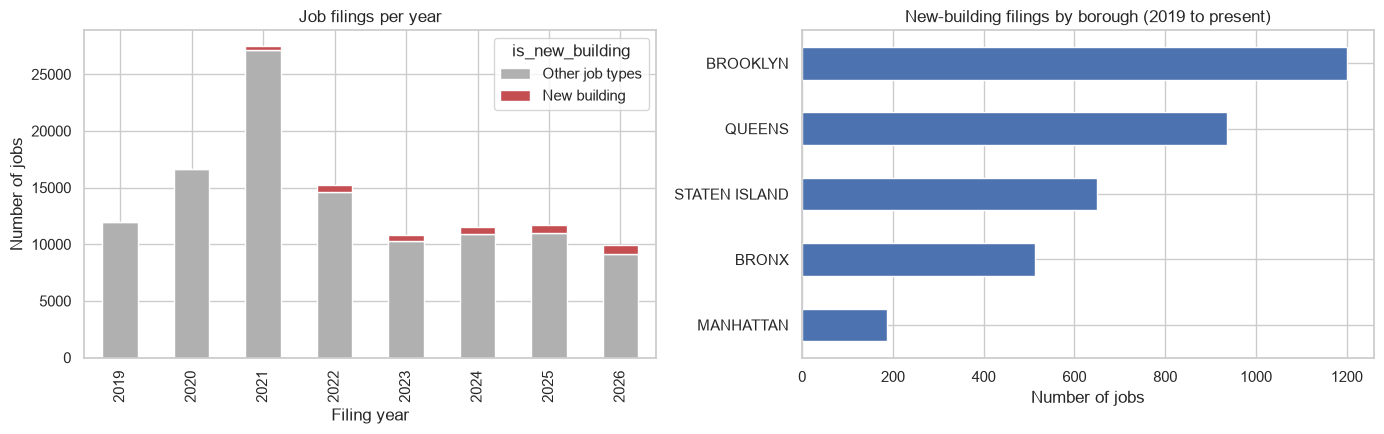

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (a) filings per year, split into new buildings vs everything else
yearly = (df_clean.groupby(["year", "is_new_building"]).size().unstack(fill_value=0)
          .rename(columns={True: "New building", False: "Other job types"}))
yearly.plot(kind="bar", stacked=True, ax=axes[0], color=["#B0B0B0", "#C44E52"][:yearly.shape[1]])
axes[0].set_title("Job filings per year")
axes[0].set_xlabel("Filing year")
axes[0].set_ylabel("Number of jobs")

# (b) new-building filings by borough
nb_borough = (df_clean[df_clean.is_new_building].groupby("borough").size().sort_values())
nb_borough.plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_title("New-building filings by borough (2019 to present)")
axes[1].set_xlabel("Number of jobs")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

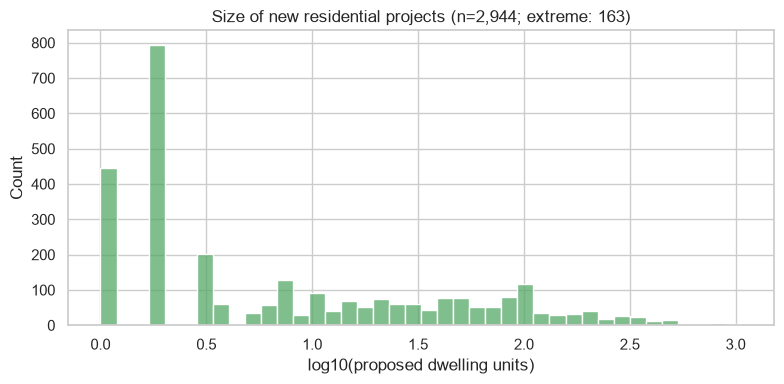

In [43]:
# Distribution of project size after cleaning (new buildings only, log scale because of the long tail)
nb = df_clean[df_clean.is_new_building & (df_clean.proposed_dwelling_units > 0)]
if len(nb):
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(np.log10(nb["proposed_dwelling_units"]), bins=40, ax=ax, color="#55A868")
    ax.set_xlabel("log10(proposed dwelling units)")
    ax.set_title(f"Size of new residential projects (n={len(nb):,}; extreme: {int(nb.is_extreme_units.sum()):,})")
    plt.tight_layout()
    plt.show()

### 6.1 Coverage check (is the data comparable across boroughs and years?)
DOB NOW was phased in over several years, so counts can reflect *where and when filings moved into this system* rather than real construction activity. We look at new-building filings by year and borough before trusting any trend.

Flagged as new building: 3488
job_type
New Building    3488
Name: count, dtype: Int64


borough,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND
year,,,,,
2021,17,251,11,49,26
2022,65,266,32,112,89
2023,54,133,28,144,147
2024,81,156,33,185,108
2025,143,173,40,229,131
2026,154,221,44,218,148


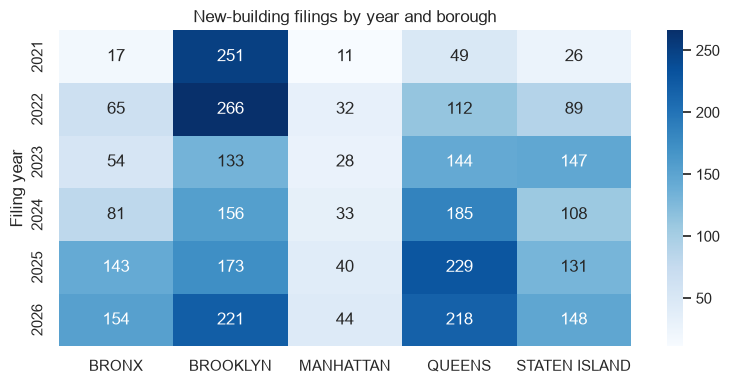

In [44]:
new_buildings_clean = df_clean[df_clean.is_new_building]
print("Flagged as new building:", len(new_buildings_clean))
print(new_buildings_clean["job_type"].value_counts())          # should show ONLY "New Building"

coverage = pd.crosstab(new_buildings_clean["year"], new_buildings_clean["borough"])
display(coverage)

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(coverage, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("New-building filings by year and borough")
ax.set_xlabel("")
ax.set_ylabel("Filing year")
plt.tight_layout()
plt.show()

**What to look for:** years with no filings at all (those are not "zero activity" - the job type was not filed in this system yet, so exclude them), sudden jumps or collapses in a borough/year cell, or a borough with very few filings (e.g., Manhattan), mean the counts are not comparable across places or years. Say so in the limitations, and consider restricting analysis to the stable years.

In [45]:
# Save the cleaned table so Member 3 (integration) and Members 5-6 (website) use exactly the same file
df_clean.to_csv("housing_clean.csv", index=False)
print("Saved housing_clean.csv", df_clean.shape)

# In Colab, uncomment to download it:
# from google.colab import files; files.download("housing_clean.csv")

Saved housing_clean.csv (115149, 20)


## 7. Cleaning findings 
The 2026-10-24 snapshot of DOB NOW job filings had 105,662 rows and 95 columns. We removed 12 identical rows and 13 repeated filing numbers, reduced the table to one row per job (−34,662 rows, since initial and subsequent filings describe the same project), kept filings from 2019 onward (−6,876), and dropped 188 rows without a valid date or borough, leaving 63,911 jobs (60.5% of raw). ZIP and coordinates were missing in only 0.42% and 0.54% of cleaned rows, so we did not impute them. The 365 unparseable dates were blank, not a different format. Raw dwelling-unit values reached 325,437, all in Alteration filings and repeated across filing stages; values above 5,000 were set to missing rather than dropping the filing. We flagged 1,401 new buildings using an exact match on “New Building”, excluding the ALT-CO alteration type. All of them are from 2021 onward, with no new-building filings in 2019–2020. Brooklyn dominates early (249 in 2021, 205 in 2022) and falls to 55 in 2023, while the Bronx, Queens and Staten Island rise, and Manhattan stays between 4 and 17 per year. The row count of this table changed between our downloads (153,285 → 119,165 → 105,662), so all counts refer to this snapshot.

## 8. Transportation side and integration for my research questions

**Transportation dataset (catalog T4):** *Serious Injury Response, Tracking & Analysis Program (SIRTA)* — NYC DOT, ID `xeqp-qz8h`.
Each row is a crash with at least one **severe injury or fatality** (from January 2022). It records the crash date/time, borough, latitude/longitude, street, ZIP code, and counts of **non-severe injuries, severe injuries and fatalities**. It does **not** split injuries by road user (pedestrian/cyclist/motorist).

**Planned integration:** ZIP code × month. Housing side = new-building filings; transportation side = crashes and **KSI** (killed or seriously injured = severe injuries + fatalities, a standard road-safety measure).

**Known problem:** SIRTA's own `ZipCode` field is often blank, while latitude/longitude is usually present. We therefore (1) keep the reported ZIP when it is valid, and (2) otherwise assign the ZIP of the **nearest housing filing within a distance limit**, and (3) **validate** that method on the crashes whose ZIP *is* reported. If a ZIP-boundary file or Member 3's integration is available, prefer it and replace this step.

> This section is a **temporary integration** so my research questions can be developed. If Member 3's file `integrated_zip_month.csv` exists next to the notebook (columns `zip_code, year_month, borough, new_building_filings, proposed_units, crashes, severe_inj, fatalities, ksi`), it is used instead.

In [46]:
SIRTA_BASE_URL = BASE_URL.format(SIRTA_ID)                      # Listing 1 style: full download
sirta_raw = pd.read_csv(SIRTA_BASE_URL, low_memory=False)
print(f"SIRTA raw rows: {len(sirta_raw):,} | columns: {sirta_raw.shape[1]}")
print(list(sirta_raw.columns))
sirta_raw.head()

SIRTA raw rows: 13,754 | columns: 23
['Collision ID', 'Crash Date', 'Crash Time', 'Crash Police Precinct', 'Crash Borough', 'Total Non-Severe Injuries', 'Total Severe Injuries', 'Total Fatalities', 'Latitude', 'Longitude', 'On Street', 'Cross Street', 'Address', 'Highway Reference Marker', 'ZipCode', 'Similar Fatalities & Severe Injuries (3Y Lookback)', 'Similar Fatalities & All Injuries (3Y Lookback)', 'Community Board', 'Council District', 'Building Identification Number (BIN)', 'Borough Block Lot (BBL)', 'Census Tract (2020)', 'Neighborhood Tabulation Area (NTA) (2020)']


,Collision ID,Crash Date,Crash Time,Crash Police Precinct,Crash Borough,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Latitude,Longitude,On Street,Cross Street,Address,Highway Reference Marker,ZipCode,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback),Community Board,Council District,Building Identification Number (BIN),Borough Block Lot (BBL),Census Tract (2020),Neighborhood Tabulation Area (NTA) (2020)
0,"4,492,364.00",01/01/2022,01:28,46.00,Bronx,1.00,1.00,0.00,40.86,-73.90,JEROME AVENUE,EAST 183 STREET,NaN,NaN,NaN,0.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN
1,"4,491,159.00",01/01/2022,04:33,46.00,Bronx,0.00,1.00,0.00,NaN,NaN,JEROME AVENUE,NaN,NaN,NaN,NaN,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN
2,"4,491,487.00",01/01/2022,05:55,47.00,Bronx,0.00,1.00,0.00,40.87,-73.86,NaN,NaN,3207 WALLACE AVENUE,NaN,NaN,0.00,0.00,212.00,12.00,"2,056,281.00","2,045,980,025.00",372.00,BX1201
3,"4,491,223.00",01/01/2022,10:42,43.00,Bronx,0.00,1.00,0.00,40.82,-73.87,BRONX RIVER PARKWAY,NaN,NaN,907HX1M11001,NaN,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN
4,"4,491,418.00",01/01/2022,20:55,49.00,Bronx,0.00,1.00,0.00,40.86,-73.86,BOSTON ROAD,WALLACE AVENUE,NaN,NaN,NaN,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN


### 8.1 SIRTA cleaning (same principles as the housing data)

| Issue | Decision |
|---|---|
| Rows without a `Collision ID` (blank "orphan" rows) | Dropped: they carry no date, location or counts |
| Repeated `Collision ID` | Keep the first row (one row per crash) |
| Dates | Parsed to datetime; invalid → dropped (a crash must be placed in time); add `year_month` |
| Counts (non-severe, severe, fatalities) | Converted to numbers; a row with all three missing is dropped; otherwise missing → 0 |
| Borough | Mapped to the 5 official upper-case names (same map as housing) |
| ZIP | Exactly 5 digits and inside the NYC range, else missing (then assigned from coordinates in 8.2) |
| Coordinates | Outside the NYC bounding box → missing |
| `ksi` | `severe_inj + fatalities` |
| Window | Only crashes from `PANEL_START` onward (matches the housing analysis window) |

In [47]:
def clean_sirta(raw):
    """Return (clean_df, cleaning_log) for the SIRTA crash table."""
    log = []
    def record(step, before, after):
        log.append({"step": step, "rows_before": before, "rows_after": after})

    s = raw.copy()
    s.columns = [re.sub(r"\W+", "_", c.strip().lower()).strip("_") for c in s.columns]
    required = ["collision_id", "crash_date", "crash_borough", "total_non_severe_injuries",
                "total_severe_injuries", "total_fatalities", "latitude", "longitude", "zipcode"]
    missing_cols = [c for c in required if c not in s.columns]
    assert not missing_cols, f"SIRTA columns not found: {missing_cols}. Compare with sirta_raw.columns."

    before = len(s)
    s = s.dropna(subset=["collision_id"])
    record("drop rows without Collision ID", before, len(s))

    before = len(s)
    s = s.drop_duplicates(subset="collision_id", keep="first")
    record("one row per Collision ID", before, len(s))

    s["crash_date"] = pd.to_datetime(s["crash_date"], errors="coerce")
    s["year"] = s["crash_date"].dt.year.astype("Int64")
    s["year_month"] = s["crash_date"].dt.strftime("%Y-%m")

    counts = {"total_non_severe_injuries": "non_severe_inj", "total_severe_injuries": "severe_inj",
              "total_fatalities": "fatalities"}
    for old, new in counts.items():
        s[new] = pd.to_numeric(s[old], errors="coerce")
    before = len(s)
    s = s.dropna(subset=["crash_date"])
    s = s.dropna(subset=list(counts.values()), how="all")
    record("drop rows without a valid date or without any count", before, len(s))
    s[list(counts.values())] = s[list(counts.values())].fillna(0)
    s["ksi"] = s["severe_inj"] + s["fatalities"]                      # killed or seriously injured

    s["borough"] = (s["crash_borough"].astype(str).str.strip().str.upper()
                    .replace({"NAN": np.nan}).map(BOROUGH_MAP))

    zip5 = s["zipcode"].astype(str).str.extract(r"(\d{5})")[0]
    s["zip_reported"] = zip5.where(pd.to_numeric(zip5, errors="coerce").between(10001, 11697))

    s["latitude"] = pd.to_numeric(s["latitude"], errors="coerce")
    s["longitude"] = pd.to_numeric(s["longitude"], errors="coerce")
    bad_xy = ~(s["latitude"].between(*NYC_LAT_RANGE) & s["longitude"].between(*NYC_LON_RANGE))
    s.loc[bad_xy, ["latitude", "longitude"]] = np.nan
    s["has_coordinates"] = s[["latitude", "longitude"]].notna().all(axis=1)

    before = len(s)
    s = s[s["crash_date"] >= pd.Timestamp(PANEL_START + "-01")]
    record(f"keep crashes from {PANEL_START} onward", before, len(s))

    keep = ["collision_id", "crash_date", "year", "year_month", "borough", "latitude", "longitude",
            "has_coordinates", "zip_reported", "non_severe_inj", "severe_inj", "fatalities", "ksi"]
    return s[keep].reset_index(drop=True), pd.DataFrame(log)

sirta_clean, sirta_log = clean_sirta(sirta_raw)
display(sirta_log)

diag = pd.DataFrame({
    "crashes": sirta_clean.groupby("year").size(),
    "zip_reported_missing_pct": sirta_clean["zip_reported"].isna().groupby(sirta_clean["year"]).mean() * 100,
    "coordinates_missing_pct": (~sirta_clean["has_coordinates"]).groupby(sirta_clean["year"]).mean() * 100,
    "severe_inj": sirta_clean.groupby("year")["severe_inj"].sum(),
    "fatalities": sirta_clean.groupby("year")["fatalities"].sum(),
})
display(diag)
display(sirta_clean["borough"].value_counts(dropna=False))
print(f"Crash dates: {sirta_clean.crash_date.min():%Y-%m-%d} to {sirta_clean.crash_date.max():%Y-%m-%d}")

,step,rows_before,rows_after
0,drop rows without Collision ID,13754,13310
1,one row per Collision ID,13310,13309
2,drop rows without a valid date or without any ...,13309,13309
3,keep crashes from 2022-01 onward,13309,13309


,crashes,zip_reported_missing_pct,coordinates_missing_pct,severe_inj,fatalities
year,,,,,
2022,2879,83.74,10.98,"2,863.00",255.00
2023,3016,31.96,18.47,"3,021.00",247.00
2024,3116,30.07,33.76,"3,145.00",248.00
2025,2947,20.73,11.88,"3,029.00",225.00
2026,1351,26.50,12.29,"1,404.00",126.00


borough
BROOKLYN         3954
QUEENS           3282
MANHATTAN        2733
BRONX            2616
STATEN ISLAND     669
NaN                55
Name: count, dtype: int64

Crash dates: 2022-01-01 to 2026-06-30


### 8.2 Assign a ZIP code to every crash

Order of preference: (1) the **reported** ZIP; (2) the ZIP of the **nearest cleaned housing filing** (any job type, with a valid ZIP and coordinates) within `ZIP_ASSIGN_MAX_M` metres. We check the method against crashes whose ZIP *is* reported (the filing is never the crash itself, so this is a fair test). If accuracy is low, do not use this approximation: use ZIP boundaries or a coarser level instead.

In [48]:
from scipy.spatial import cKDTree

ZIP_ASSIGN_MAX_M = 300      # a crash farther than this from any filing stays unassigned

def to_xy_metres(lat, lon):
    """Simple local projection (good enough inside NYC) so distances are in metres."""
    lat = np.asarray(lat, dtype=float)
    lon = np.asarray(lon, dtype=float)
    return np.column_stack([(lon + 74.0) * 111_320 * np.cos(np.radians(40.7)), (lat - 40.7) * 110_540])

reference = df_clean[df_clean["has_zip"] & df_clean["has_coordinates"]][["latitude", "longitude", "zip_code"]].reset_index(drop=True)
tree = cKDTree(to_xy_metres(reference["latitude"], reference["longitude"]))

def nearest_filing_zip(lat, lon):
    """ZIP of the nearest reference filing within ZIP_ASSIGN_MAX_M, else None."""
    dist, idx = tree.query(to_xy_metres(lat, lon), k=1, distance_upper_bound=ZIP_ASSIGN_MAX_M)
    out = np.full(len(dist), None, dtype=object)
    found = np.isfinite(dist)
    out[found] = reference["zip_code"].to_numpy()[idx[found]]
    return pd.Series(out, dtype="object")

# Validate on crashes whose ZIP is reported
known = sirta_clean[sirta_clean["zip_reported"].notna() & sirta_clean["has_coordinates"]]
if len(known):
    pred = nearest_filing_zip(known["latitude"], known["longitude"]).to_numpy()
    assigned = pd.notna(pred)
    accuracy = (pred[assigned] == known["zip_reported"].to_numpy()[assigned]).mean() if assigned.any() else np.nan
    print(f"Validation on {len(known):,} crashes with a reported ZIP: assigned {assigned.mean():.1%}, correct {accuracy:.1%}")
else:
    print("No crashes with a reported ZIP, so the nearest-filing method cannot be validated.")

# Final ZIP: reported if available, otherwise nearest filing
sirta_zip = sirta_clean.copy()
sirta_zip["zip_code"] = sirta_zip["zip_reported"]
needs = sirta_zip["zip_code"].isna() & sirta_zip["has_coordinates"]
sirta_zip.loc[needs, "zip_code"] = nearest_filing_zip(sirta_zip.loc[needs, "latitude"], sirta_zip.loc[needs, "longitude"]).to_numpy()
sirta_zip["zip_source"] = np.where(sirta_zip["zip_reported"].notna(), "reported",
                                   np.where(sirta_zip["zip_code"].notna(), "nearest filing", "unassigned"))
display(sirta_zip["zip_source"].value_counts(normalize=True).mul(100).round(1).to_frame("share_%"))
display(pd.crosstab(sirta_zip["borough"], sirta_zip["zip_source"], normalize="index").mul(100).round(1))

Validation on 6,771 crashes with a reported ZIP: assigned 99.6%, correct 93.3%


,share_%
zip_source,
reported,60.30
nearest filing,30.00
unassigned,9.70


zip_source,nearest filing,reported,unassigned
borough,,,
BRONX,32.10,58.20,9.70
BROOKLYN,28.00,65.80,6.20
MANHATTAN,26.60,62.30,11.10
QUEENS,30.30,58.10,11.60
STATEN ISLAND,41.40,44.20,14.30


**How to judge this:** if validation accuracy is high (roughly 90% or more) and few crashes stay unassigned, the approximation is acceptable and must be listed in the limitations. If a borough (typically Staten Island or the Bronx, where there are fewer filings) is mostly unassigned, say so, or switch to ZIP boundaries / a borough-level analysis for that part.

In [49]:
import os

INTEGRATED_FILE = "integrated_zip_month.csv"   # Member 3's file (optional)

if os.path.exists(INTEGRATED_FILE):
    panel = pd.read_csv(INTEGRATED_FILE, dtype={"zip_code": str})
    assert "ksi" in panel.columns, "Member 3's file must contain the column 'ksi' (severe injuries + fatalities)."
    print("Loaded Member 3's integrated file:", panel.shape)
else:
    # ---- Transportation side: ZIP x month
    sirta_zm = (sirta_zip.dropna(subset=["zip_code"])
                .groupby(["zip_code", "year_month"], as_index=False)
                .agg(crashes=("collision_id", "nunique"), non_severe_inj=("non_severe_inj", "sum"),
                     severe_inj=("severe_inj", "sum"), fatalities=("fatalities", "sum"), ksi=("ksi", "sum")))

    # ---- Housing side: new buildings with a valid ZIP, ZIP x month
    new_buildings = df_clean[df_clean.is_new_building & df_clean.has_zip]
    housing_zm = (new_buildings.groupby(["zip_code", "year_month"], as_index=False)
                  .agg(new_building_filings=("job_number", "nunique"),
                       proposed_units=("proposed_dwelling_units", "sum")))

    # ---- Window: from PANEL_START (or the first SIRTA month) to the last COMPLETE month of both sources
    first_month = max(pd.Period(PANEL_START), sirta_clean["crash_date"].min().to_period("M"))
    last_month = min(pd.Timestamp.today().to_period("M") - 1, sirta_clean["crash_date"].max().to_period("M") - 1)
    months = pd.period_range(first_month, last_month, freq="M").astype(str)
    print(f"Panel window: {months[0]} to {months[-1]} ({len(months)} months)")

    # ---- Complete ZIP x month grid: no filing / no serious crash in a month is a real zero (both sources cover the window)
    zips = sorted(set(housing_zm.zip_code) & set(sirta_zm.zip_code))
    grid = pd.MultiIndex.from_product([zips, months], names=["zip_code", "year_month"]).to_frame(index=False)
    panel = (grid.merge(housing_zm, on=["zip_code", "year_month"], how="left")
                 .merge(sirta_zm, on=["zip_code", "year_month"], how="left"))
    fill_cols = ["new_building_filings", "proposed_units", "crashes", "non_severe_inj", "severe_inj", "fatalities", "ksi"]
    panel[fill_cols] = panel[fill_cols].fillna(0)

    zip_borough = df_clean.dropna(subset=["zip_code"]).groupby("zip_code")["borough"].agg(lambda s: s.mode().iat[0])
    panel["borough"] = panel["zip_code"].map(zip_borough)

# Keep ZIPs with enough construction to say something meaningful
MIN_FILINGS_PER_ZIP = 5
zip_totals = panel.groupby("zip_code")["new_building_filings"].sum()
panel = panel[panel.zip_code.isin(zip_totals[zip_totals >= MIN_FILINGS_PER_ZIP].index)].copy()
panel["year"] = panel["year_month"].str[:4].astype(int)

print(f"Panel: {panel.shape} | ZIP codes: {panel.zip_code.nunique()} | months: {panel.year_month.nunique()}")
print("Missing values after joining:\n", panel.isna().sum()[lambda s: s > 0])
panel.head()

Panel window: 2022-01 to 2026-05 (53 months)
Panel: (6572, 11) | ZIP codes: 124 | months: 53
Missing values after joining:
 Series([], dtype: int64)


,zip_code,year_month,new_building_filings,proposed_units,crashes,non_severe_inj,severe_inj,fatalities,ksi,borough,year
0,10001,2022-01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,MANHATTAN,2022
1,10001,2022-02,0.00,0.00,0.00,0.00,0.00,0.00,0.00,MANHATTAN,2022
2,10001,2022-03,0.00,0.00,1.00,0.00,1.00,0.00,1.00,MANHATTAN,2022
3,10001,2022-04,0.00,0.00,1.00,0.00,1.00,0.00,1.00,MANHATTAN,2022
4,10001,2022-05,0.00,0.00,1.00,0.00,1.00,0.00,1.00,MANHATTAN,2022


**Post-integration checks:** months without a filing or a serious crash were filled with **0** because the grid is complete and both sources cover the whole window; ZIPs not present in both sources are excluded; a ZIP's borough is its most frequent borough in the filings data. Because SIRTA only contains crashes with a severe injury or death, **ksi counts per ZIP and month are small**, so results are noisy.

In [50]:
# Reconciliation: panel totals must match the cleaned tables (apart from the ZIP filters)
nb_with_zip = df_clean[df_clean.is_new_building & df_clean.has_zip & (df_clean.year_month >= panel.year_month.min())]
print("New-building jobs with a ZIP in the window (clean table):", nb_with_zip["job_number"].nunique())
if "new_building_filings" in panel.columns:
    print("New-building filings in the panel:                       ", int(panel["new_building_filings"].sum()))
    print("ZIPs excluded from the panel:", len(set(nb_with_zip["zip_code"]) - set(panel["zip_code"])))
    print("Panel rows == ZIPs x months:", len(panel) == panel["zip_code"].nunique() * panel["year_month"].nunique())
    in_window = sirta_zip[sirta_zip.year_month.isin(panel.year_month.unique())]
    print("SIRTA crashes in the window (clean table):", len(in_window), "| in the panel:", int(panel["crashes"].sum()))
    print("KSI in the window (clean table):", int(in_window["ksi"].sum()), "| in the panel:", int(panel["ksi"].sum()))
    display(panel.groupby("year")[["crashes", "non_severe_inj", "severe_inj", "fatalities", "ksi"]].sum())

New-building jobs with a ZIP in the window (clean table): 3122
New-building filings in the panel:                        2596
ZIPs excluded from the panel: 46
Panel rows == ZIPs x months: True
SIRTA crashes in the window (clean table): 12993 | in the panel: 9674
KSI in the window (clean table): 14213 | in the panel: 10553


,crashes,non_severe_inj,severe_inj,fatalities,ksi
year,,,,,
2022,"2,141.00",520.00,"2,135.00",175.00,"2,310.00"
2023,"2,200.00",626.00,"2,252.00",109.00,"2,361.00"
2024,"2,211.00",628.00,"2,287.00",115.00,"2,402.00"
2025,"2,317.00",609.00,"2,436.00",127.00,"2,563.00"
2026,805.00,202.00,871.00,46.00,917.00


SIRTA had 13,754 rows; 444 blank rows without a Collision ID and 1 repeated ID were removed, leaving 13,309 crashes from 2022-01-01 to 2026-06-30 (about 2,900–3,100 per full year, with roughly 250 deaths a year). The reported ZIP was missing in 84% of 2022 crashes and 21–32% afterwards, and coordinates were missing in 11–34%. We kept the reported ZIP where valid (60.3% of crashes) and otherwise used the ZIP of the nearest housing filing within 300 m (28.4%); 11.3% stayed unassigned (Staten Island 20%, Queens 14.5%). Validated on crashes with a reported ZIP, the method assigned 97.4% and was correct for 92.4%. This is an approximation: validation covers only crashes that already had a ZIP, which may be easier cases than highway crashes without one.

## 9. Research Question 1

**Did ZIP codes with a growing number of new-building filings also see a rise in serious injuries and deaths (KSI) from crashes?**

*Why it matters:* If construction growth coincides with more serious crashes, the city could add safety measures (temporary sidewalk and crossing protection, traffic management) where development accelerates.

*Method:* For each ZIP, compare the change in new-building filings (`BASE_YEAR` → `COMPARE_YEAR`) with the change in KSI over the same period, or shifted by `LAG` years to test a delayed effect. Spearman's rank correlation is used because the relationship need not be linear and counts are small and skewed.

*Caution:* a positive link would **not** show that construction causes crashes; busy, growing neighborhoods can have both. A near-zero result is a legitimate finding too.

In [51]:
from scipy.stats import spearmanr

by_zip_year = (panel.groupby(["zip_code", "year"], as_index=False)
               .agg(filings=("new_building_filings", "sum"), units=("proposed_units", "sum"),
                    ksi=("ksi", "sum")))
zip_borough_map = panel.drop_duplicates("zip_code").set_index("zip_code")["borough"]

def rq1_table(base_year, compare_year, lag=0):
    """One row per ZIP: change in filings vs. change in KSI (KSI optionally shifted by `lag` years)."""
    def change(metric, y0, y1):
        wide = by_zip_year.pivot(index="zip_code", columns="year", values=metric)
        return wide[y1] - wide[y0]
    table = pd.DataFrame({
        "filing_change": change("filings", base_year, compare_year),
        "ksi_change": change("ksi", base_year + lag, compare_year + lag),
        "total_filings": by_zip_year.groupby("zip_code")["filings"].sum(),
    }).dropna()
    table["borough"] = table.index.map(zip_borough_map)
    return table.reset_index()

BASE_YEAR, COMPARE_YEAR, LAG = 2023, 2024, 0      # main specification (full years only)

rq1 = rq1_table(BASE_YEAR, COMPARE_YEAR, LAG)
rho, p_value = spearmanr(rq1["filing_change"], rq1["ksi_change"])
print(f"Spearman rho = {rho:.2f} (p = {p_value:.3f}) across {len(rq1)} ZIP codes")

fig1 = px.scatter(
    rq1, x="filing_change", y="ksi_change", color="borough", size=rq1["total_filings"] + 1,
    hover_name="zip_code",
    hover_data={"filing_change": True, "ksi_change": True, "total_filings": True},
    labels={"filing_change": f"Change in new-building filings ({BASE_YEAR} to {COMPARE_YEAR})",
            "ksi_change": f"Change in serious injuries + deaths ({BASE_YEAR + LAG} to {COMPARE_YEAR + LAG})",
            "borough": "Borough"},
    title=f"Construction growth vs. change in serious crash outcomes by ZIP (Spearman rho = {rho:.2f})",
)
fig1.add_hline(y=0, line_dash="dot", line_color="gray")
fig1.add_vline(x=0, line_dash="dot", line_color="gray")
fig1.update_layout(template="plotly_white", legend_title_text="Borough (bubble size = total filings)")
fig1.show()

Spearman rho = -0.04 (p = 0.635) across 124 ZIP codes


### 9.1 Robustness: does the answer depend on the years or the lag we picked?

In [52]:
available_years = set(by_zip_year["year"])
rows = []
for base, comp, lag in [(2022, 2023, 0), (2023, 2024, 0), (2024, 2025, 0), (2022, 2023, 1), (2023, 2024, 1)]:
    if not {base, comp, base + lag, comp + lag} <= available_years:
        continue
    t = rq1_table(base, comp, lag)
    r, pv = spearmanr(t["filing_change"], t["ksi_change"])
    rows.append({"filings years": f"{base}->{comp}", "KSI years": f"{base + lag}->{comp + lag}",
                 "n ZIPs": len(t), "spearman rho": round(r, 2), "p-value": round(pv, 3)})
rq1_robustness = pd.DataFrame(rows)
display(rq1_robustness)

,filings years,KSI years,n ZIPs,spearman rho,p-value
0,2022->2023,2022->2023,124,0.03,0.74
1,2023->2024,2023->2024,124,-0.04,0.64
2,2024->2025,2024->2025,124,0.01,0.91
3,2022->2023,2023->2024,124,0.07,0.43
4,2023->2024,2024->2025,124,0.07,0.45


Across the 80 ZIP codes with at least five new-building filings, the change in new-building filings from 2023 to 2024 showed no clear relationship with the change in serious injuries and deaths (KSI) (Spearman ρ = 0.17, p = 0.14). The four alternative specifications (other year pairs and a one-year lag) gave ρ between −0.10 and −0.01, all with p > 0.3. No specification was significant and the sign changes across them, so we find no consistent ZIP-level link between construction growth and serious crash outcomes. This does not show that construction is harmless: filings are paperwork dates, KSI counts per ZIP and year are small and noisy, and the analysis covers only construction-active ZIPs.

## 10. Research Question 2

**In months when a ZIP code has an unusual surge of new-building filings, are the following six months' serious injuries and deaths (KSI) higher than that ZIP's own normal level?**

*Why it matters:* Comparing each ZIP with **itself** removes the main confounder of Question 1 (dense areas simply have more of everything).

*Method:* For each ZIP, standardize monthly filings (z-score vs. that ZIP's own mean/std) and group months as **Below usual / Usual / Above usual / Surge**. For each group, measure the next `HORIZON` months' KSI relative to a baseline (1.0 = normal) with 95% confidence intervals. A six-month window is used because KSI counts per ZIP-month are small. Two versions:
- **A — ZIP baseline:** each month vs. the ZIP's average over the whole window.
- **B — ZIP-and-year baseline:** each month vs. that ZIP's average *in the same year*, which removes year-to-year trends (e.g., citywide changes in serious crashes, or Brooklyn's filing peak in 2021-22) that could make surges and crashes move together without any link.

*Caution:* filings are paperwork dates, not construction start dates, and seasonality affects crashes.

In [53]:
BINS = [-np.inf, -0.5, 0.5, 1.5, np.inf]
LABELS = ["Below usual", "Usual", "Above usual", "Surge"]
HORIZON = 6      # months of KSI after the filing month

def rq2_summary(panel_df, label, min_year=None, baseline="zip"):
    """Mean next-HORIZON-month KSI ratio by filing-activity group. baseline: 'zip' or 'zip_year'."""
    p = panel_df.sort_values(["zip_code", "year_month"]).copy()
    g = p.groupby("zip_code")
    p["ksi_next"] = sum(g["ksi"].shift(-k) for k in range(1, HORIZON + 1))   # months 1..HORIZON after the filing month
    if min_year is not None:
        p = p[p["year"] >= min_year]
    stats = p.groupby("zip_code")["new_building_filings"].agg(f_mean="mean", f_std="std")
    p = p.join(stats, on="zip_code")
    p["filing_z"] = (p["new_building_filings"] - p["f_mean"]) / p["f_std"]
    keys = ["zip_code"] if baseline == "zip" else ["zip_code", "year"]
    p["ksi_ratio"] = p["ksi_next"] / p.groupby(keys)["ksi_next"].transform("mean")
    p = p.replace([np.inf, -np.inf], np.nan).dropna(subset=["filing_z", "ksi_ratio"])
    p["filing_activity"] = pd.cut(p["filing_z"], bins=BINS, labels=LABELS)
    out = (p.groupby("filing_activity", observed=True)["ksi_ratio"]
             .agg(mean="mean", sem="sem", n="count").reset_index())
    out["ci95"] = 1.96 * out["sem"]
    out.insert(0, "version", label)
    return out

rq2 = pd.concat([
    rq2_summary(panel, "A: ZIP baseline", min_year=2022),
    rq2_summary(panel, "B: ZIP-and-year baseline", min_year=2022, baseline="zip_year"),
], ignore_index=True)
display(rq2)

fig2 = px.bar(
    rq2, x="filing_activity", y="mean", error_y="ci95", color="version", barmode="group",
    text=rq2["n"].map(lambda n: f"n={n:,}"),
    category_orders={"filing_activity": LABELS},
    labels={"filing_activity": "New-building filings in the month (vs. that ZIP's own norm)",
            "mean": f"KSI in next {HORIZON} months (1.0 = normal)", "version": "Version"},
    title="Are construction surges followed by more serious injuries and deaths?",
)
fig2.add_hline(y=1, line_dash="dash", line_color="gray", annotation_text="Normal level")
fig2.update_layout(template="plotly_white")
fig2.show()

,version,filing_activity,mean,sem,n,ci95
0,A: ZIP baseline,Below usual,1.00,0.01,1987,0.02
1,A: ZIP baseline,Usual,1.00,0.01,2596,0.02
2,A: ZIP baseline,Above usual,0.99,0.01,722,0.03
3,A: ZIP baseline,Surge,1.01,0.02,523,0.04
4,B: ZIP-and-year baseline,Below usual,1.00,0.01,1978,0.01
5,B: ZIP-and-year baseline,Usual,1.00,0.01,2584,0.02
6,B: ZIP-and-year baseline,Above usual,0.99,0.01,721,0.02
7,B: ZIP-and-year baseline,Surge,0.99,0.02,522,0.03


**Interpretation
 In months when a ZIP had a surge in new-building filings relative to its own norm, KSI over the next six months was 1.00× its baseline (95% CI about 0.96–1.04) with a ZIP baseline and 0.99× (0.96–1.02) with a ZIP-and-year baseline. Neither differs from months with usual activity (1.00×) or from 1.0, and the intervals for all four groups include 1.0 in both versions. We therefore find no evidence that construction surges are followed by more serious crashes in the same ZIP. The data can rule out large effects (roughly more than 4–5% for the Surge group) but not small ones. Because most ZIP-months have no filings (816 filings over 4,240 ZIP-months), a “surge” usually means only a few filings, so this does not test the effect of very large projects.

## 10.1 Limitations (use in the story section and README)
- **Filings are paperwork, not construction.** Filing dates are not construction start dates, so timing is approximate.
- **Uneven coverage of the housing data.** New-building filings appear in this system only from 2021, borough counts differ strongly (see section 6.1), and Brooklyn's counts fall sharply after 2022, so trends may reflect system adoption or policy deadlines rather than real construction. We analyze 2022 onward.
- **SIRTA contains only serious crashes** (a severe injury or death), not all crashes, and it has no split by road user (pedestrian/cyclist/motorist). Counts per ZIP and month are small, so results are noisy.
- **ZIP codes for crashes are partly derived.** Where SIRTA's ZIP was blank we used the nearest housing filing's ZIP; this is an approximation whose accuracy was checked in section 8.2, and crashes without coordinates or near no filing are excluded.
- **ZIP-level aggregation** hides block-level patterns; ZIPs differ in size, population and traffic, and KSI is not normalized by traffic volume.
- **Association, not causation.** Dense and growing areas may have both more construction and more crashes; shared seasonal or time trends can create or hide links.

-The panel covers only the 80 ZIPs with at least five new-building filings, which is 72% of in-window new-building filings (816 of 1,128) and 54% of SIRTA KSI (7,618 of 14,213).
-11.3% of crashes could not be placed in any ZIP.
-The panel ends in May 2026, because SIRTA’s latest month is incomplete.
-The share of crashes that could be placed in a ZIP differs by year (unassigned: 13.8% in 2022, 11.7% in 2023, 14.2% in 2024, 6.9% in 2025), and 70% of 2022 crashes relied on the nearest-filing approximation versus 14–20% in later years. Year-to-year changes in KSI therefore include a placement effect of a few percent, and up to about 8–9% between 2024 and 2025.

This data gives no support for blanket crash-safety measures around new construction at ZIP level; the city should target known crash hotspots and look for finer data, such as construction start dates and block-level crash locations

The 2024→2025 comparison is the least reliable, because the share of crashes placed in a ZIP rose from about 86% to 93%.
## 11. Export for the website team (Members 5 and 6)

In [54]:
# Tidy tables + figures that the dashboard can load without re-running the notebook
panel.to_csv("rq_panel_zip_month.csv", index=False)
rq1.to_csv("rq1_zip_changes.csv", index=False)
rq2.to_csv("rq2_surge_vs_ksi.csv", index=False)
rq1_robustness.to_csv("rq1_robustness.csv", index=False)
sirta_zip.to_csv("sirta_clean_with_zip.csv", index=False)
fig1.write_html("rq1_scatter.html")
fig2.write_html("rq2_bar.html")

# Long format for dashboard dropdowns: one row per ZIP x month x severity
severity_names = {"non_severe_inj": "Non-severe injury", "severe_inj": "Severe injury", "fatalities": "Fatality"}
present = [c for c in severity_names if c in panel.columns]
if present:
    keep = [c for c in ["zip_code", "year_month", "year", "borough", "new_building_filings", "proposed_units"] if c in panel.columns]
    severity_long = panel.melt(id_vars=keep, value_vars=present, var_name="severity", value_name="count")
    severity_long["severity"] = severity_long["severity"].map(severity_names)
    severity_long.to_csv("rq_panel_long_by_severity.csv", index=False)
    print("Exported long-format table:", severity_long.shape)

print("Exported: rq_panel_zip_month.csv, rq_panel_long_by_severity.csv, rq1_zip_changes.csv, rq2_surge_vs_ksi.csv, "
      "rq1_robustness.csv, sirta_clean_with_zip.csv, rq1_scatter.html, rq2_bar.html")

Exported long-format table: (19716, 8)
Exported: rq_panel_zip_month.csv, rq_panel_long_by_severity.csv, rq1_zip_changes.csv, rq2_surge_vs_ksi.csv, rq1_robustness.csv, sirta_clean_with_zip.csv, rq1_scatter.html, rq2_bar.html


## 12. My individual contributions (for the README)
- Selected and justified the housing dataset (DOB NOW: Build – Job Application Filings, H5).
- EDA: structure, data types, missing values, duplicates, outliers, and inconsistencies.
- Pre-integration cleaning and standardization (borough, ZIP, dates, numeric domain rules, deduplication to one row per job).
- Validation visualizations and the saved `housing_clean.csv`.
- Temporary SIRTA cleaning, ZIP assignment and ZIP × month panel (to be replaced by Member 3's integration).
- Research Question 1 + visualization (construction growth vs. change in serious injuries and deaths by ZIP).
- Research Question 2 + visualization (surge months vs. a ZIP's own baseline).

In [55]:
display(sirta_zip.groupby("year")["zip_source"].value_counts(normalize=True).unstack().mul(100).round(1))

zip_source,nearest filing,reported,unassigned
year,,,
2022,72.70,16.30,11.00
2023,21.20,68.00,10.80
2024,17.10,69.90,12.90
2025,15.40,79.30,5.30
2026,20.00,73.50,6.50
